# 🚀 Модуль 3. Урок 1. Python в эпоху AI: отказ от зубрежки синтаксиса в пользу векторных структур

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Enlyl/data-analyst-2027/blob/main/course/module_03_python/lesson_01_python_no_syntax_memorization.ipynb)

## 📌 Бизнес-контекст и методология
В 2027 году аналитику больше не нужно запоминать наизусть редкие сигнатуры функций — генеративный AI мгновенно пишет код.
Однако ключевая компетенция аналитика — **понимание вычислительной сложности и векторных операций**.
Итерация циклами `for` по миллиону строк в Python работает в сотни раз медленнее, чем векторизованные операции NumPy/Pandas, написанные на низкоуровневом C. Аналитик, использующий циклы, обрушивает ETL-пайплайны компании и переплачивает за облачные вычисления.

In [1]:
# 🚀 Универсальная инициализация окружения и данных
import os
import urllib.request
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Arial', 'Helvetica']
plt.rcParams['axes.edgecolor'] = '#e6e6e6'
plt.rcParams['axes.linewidth'] = 0.8

PRIMARY = "#1779ba"
SUCCESS = "#3adb76"
ALERT = "#cc4b37"
WARNING = "#ffae00"
SECONDARY = "#767676"

def ensure_dataset(filename, subfolder=""):
    if os.path.exists(filename):
        return filename
    candidates = [
        os.path.join("course", "datasets", subfolder, filename),
        os.path.join("course", "datasets", filename),
        os.path.join("..", "datasets", subfolder, filename),
        os.path.join("..", "datasets", filename),
        os.path.join("..", "..", "course", "datasets", subfolder, filename),
        os.path.join("datasets", subfolder, filename),
        os.path.join("datasets", filename),
    ]
    for c in candidates:
        if os.path.exists(c):
            return c
    raw_base = "https://raw.githubusercontent.com/Enlyl/data-analyst-2027/main/course/datasets"
    url = f"{raw_base}/{subfolder}/{filename}" if subfolder else f"{raw_base}/{filename}"
    urllib.request.urlretrieve(url, filename)
    return filename

saas_path = ensure_dataset("saas_users.csv", subfolder="raw")
df_saas = pd.read_csv(saas_path)
print(f"🟢 Датасет saas_users успешно загружен: {df_saas.shape[0]} строк, {df_saas.shape[1]} колонок")

🟢 Датасет saas_users успешно загружен: 2000 строк, 12 колонок


## 🔍 Разбор механики: Векторизация vs Итеративные циклы
Сравним время выполнения двух подходов на задаче пересчета ARR (Annual Recurring Revenue = MRR * 12 * дисконт-фактор):
1. Классический цикл `for` с построчным обращением
2. Векторизованное умножение столбцов в Pandas/NumPy

In [2]:
# Эксперимент производительности: Векторизация против Python for-loop
data_sizes = [1000, 10000, 50000, 200000]
loop_times = []
vector_times = []

for n in data_sizes:
    arr = np.random.uniform(10, 500, n)
    
    # 1. Цикл for
    t0 = time.perf_counter()
    res_loop = [x * 12 * 0.85 for x in arr]
    loop_times.append(time.perf_counter() - t0)
    
    # 2. Векторизация NumPy
    t0 = time.perf_counter()
    res_vec = arr * 12 * 0.85
    vector_times.append(time.perf_counter() - t0)

benchmark_df = pd.DataFrame({
    'Количество строк': data_sizes,
    'Python Loop (сек)': loop_times,
    'NumPy Vectorized (сек)': vector_times,
    'Ускорение (раз)': np.array(loop_times) / np.array(vector_times)
})
display(benchmark_df.round(4))

,Количество строк,Python Loop (сек),NumPy Vectorized (сек),Ускорение (раз)
0,1000,0.0002,0.0000,11.5942
1,10000,0.0015,0.0000,93.0060
2,50000,0.0094,0.0002,38.4774
3,200000,0.0369,0.0017,21.6084


## 📊 Визуализация бизнес-кейса: Экспоненциальный выигрыш в скорости
Сравним вычислительную масштабируемость обоих подходов. При росте объемов данных векторизация сохраняет почти мгновенный отклик.

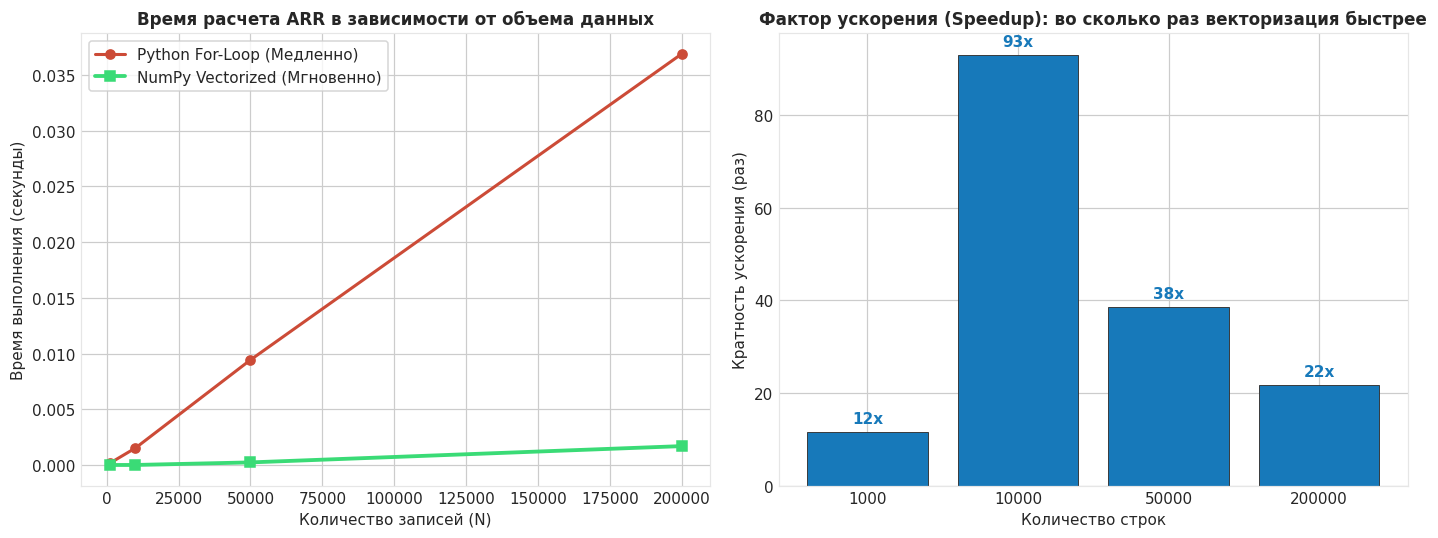

In [3]:
# Визуализация бенчмарка производительности
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5), dpi=110)

# График 1: Абсолютное время выполнения
ax1.plot(benchmark_df['Количество строк'], benchmark_df['Python Loop (сек)'], 
         marker='o', color=ALERT, linewidth=2, label='Python For-Loop (Медленно)')
ax1.plot(benchmark_df['Количество строк'], benchmark_df['NumPy Vectorized (сек)'], 
         marker='s', color=SUCCESS, linewidth=2.5, label='NumPy Vectorized (Мгновенно)')

ax1.set_title("Время расчета ARR в зависимости от объема данных", fontsize=11, fontweight='bold')
ax1.set_xlabel("Количество записей (N)")
ax1.set_ylabel("Время выполнения (секунды)")
ax1.legend(frameon=True, facecolor='#ffffff')

# График 2: Коэффициент ускорения (Speedup Factor)
bars = ax2.bar([str(x) for x in data_sizes], benchmark_df['Ускорение (раз)'], 
               color=PRIMARY, edgecolor='#333333', linewidth=0.6)
ax2.set_title("Фактор ускорения (Speedup): во сколько раз векторизация быстрее", fontsize=11, fontweight='bold')
ax2.set_xlabel("Количество строк")
ax2.set_ylabel("Кратность ускорения (раз)")

for b in bars:
    h = b.get_height()
    ax2.annotate(f"{h:.0f}x", xy=(b.get_x() + b.get_width()/2, h), xytext=(0, 4),
                 textcoords="offset points", ha='center', va='bottom', fontsize=10, fontweight='bold', color=PRIMARY)

plt.tight_layout()
plt.show()

### 🎯 Практическое задание 1: Векторизованный расчет годовой выручки (ARR)
Используя датасет `df_saas`, рассчитайте колонку `annual_revenue` как `mrr * 12` без использования циклов. Найдите суммарный ARR по всем пользователям.

In [4]:
### ВАШ КОД ЗДЕСЬ
df_saas['annual_revenue'] = df_saas['mrr'] * 12
total_arr = df_saas['annual_revenue'].sum()

print(f"Общий ARR компании: ${total_arr:,.2f}")
display(df_saas[['user_id', 'plan', 'mrr', 'annual_revenue']].head(5))

assert 'annual_revenue' in df_saas.columns, "Колонка annual_revenue должна быть создана"
assert total_arr > 0, "Суммарный ARR должен быть положительным"
print("✅ Тест успешно пройден: векторизованный расчет ARR выполнен корректно!")

Общий ARR компании: $1,896,120.00


,user_id,plan,mrr,annual_revenue
0,1,Professional,99.0,1188.0
1,2,Professional,99.0,1188.0
2,3,Starter,29.0,348.0
3,4,Professional,99.0,1188.0
4,5,Professional,99.0,1188.0


✅ Тест успешно пройден: векторизованный расчет ARR выполнен корректно!


### 💡 Архитектурный закон векторизации
Циклы в Python создают накладные расходы на проверку типов (Dynamic Dispatch) и упаковку объектов.
NumPy и Pandas выполняют математику непрерывным блоком в оперативной памяти с использованием инструкций SIMD (Single Instruction, Multiple Data) современного процессора.